# P4 실습: Transformer와 LLM

이 실습의 목표는 **모델을 새로 훈련하는 것이 아니라**, 직접 구성한 작은 숫자 예제와 이미 학습된 모델을 사용해 Transformer의 작동 원리를 관찰하는 것이다.

**실습의 흐름**
1. 텍스트 → 토큰 → 토큰 ID → 임베딩·위치 인코딩
2. Q·K·V → Self-Attention → **Multi-Head Attention**
3. **Encoder Self-Attention·Decoder Masked Self-Attention·Cross-Attention**의 차이와 **Teacher Forcing·Causal Mask** 확인
4. **Encoder–Decoder**로 영어→스페인어 번역 및 생성 토큰 관찰
5. **Decoder-only** 모델의 다음 토큰 예측, 텍스트 이어쓰기·질의응답

앞의 네 단계는 **P4 Theory의 3절까지** 배운 내용에 대응한다. 마지막 Decoder-only 실습은 이후 이론 내용을 학습할 때 다시 살펴볼 수 있다. **훈련·파인튜닝·역전파 코드는 없다.** 모든 코드는 완성형으로 제공되며, 학생은 출력과 그림을 관찰하고 질문에 답한다. **의미 검색과 RAG의 구현은 P4 Project에서 수행한다.**

## 실행 환경

- VS Code/Jupyter Notebook 또는 Google Colab에서 실행할 수 있다.
- 처음 실행하면 Hugging Face에서 **두 개의 사전훈련 모델**을 다운로드한다. 네트워크 속도에 따라 시간이 걸린다.
- PyTorch가 없는 환경이라면 별도로 `%pip install torch`를 실행한다. CPU만으로도 가능하지만 GPU보다 느릴 수 있다.
- **라이브러리 버전:** 이 노트북은 `transformers` **5.x**를 사용한다. Google Colab에서 기존 `transformers` 4.x를 업데이트했다면 **런타임 → 세션 다시 시작** 후 설치 셀 다음부터 실행한다.
- Colab에 기본 설치된 `gradio`, `diffusers`의 요구조건을 고려해 `huggingface-hub` **1.32 이상, 2 미만**을 설치한다. 환경에 따라 다른 패키지 관련 경고가 표시될 수 있으므로, 아래에서 실제 버전과 모델 실행을 확인한다.
- 설치 직후 import 오류가 발생하면 **커널을 재시작한 후 아래 셀부터** 실행한다.

**사용 모델:** `Helsinki-NLP/opus-mt-en-es`(영어→스페인어, Encoder–Decoder 계열), `HuggingFaceTB/SmolLM2-135M-Instruct`(영어 중심의 소형 Decoder-only 모델). 최신 대형 대화형 모델 수준의 정확성을 기대하지 않는다.


In [27]:
%pip install -q --upgrade "transformers==5.24.0" "huggingface-hub>=1.32,<2" sentencepiece sacremoses

In [28]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import transformers
import huggingface_hub
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM

# P4에서는 학습하지 않고 사전훈련 모델로 추론만 한다.
# Colab에서 설치 전 4.x가 이미 불러와졌다면 런타임을 재시작한다.
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("PyTorch:", torch.__version__)
assert transformers.__version__.split(".")[0] == "5", (
    "Transformers 5.x가 아닙니다. 런타임을 재시작하고 설치 셀부터 다시 실행하세요."
)


Transformers: 5.24.0
Hugging Face Hub: 1.33.0
PyTorch: 2.14.1+cpu


---
## 텍스트를 숫자로 표현하는 과정 확인

이 실습에서는 **하나의 문장** `The unbelievable red car is fast.`를 사용해 표준화, 토큰화, 어휘집, 임베딩과 위치 인코딩을 살펴본다.

먼저 모델 다운로드가 필요 없는 **교육용 예제**에서 단어 기준 토큰 7개, 수업용 ID 10~16, 임베딩 차원 256을 사용한다. 이후 **이미 학습된 번역 모델의 실제 토크나이저와 가중치**를 확인한다. 실습 내내 모델은 **직접 훈련하지 않는다.**


### 표준화: 띄어쓰기 정리하기

**표준화**(Text Standardization)는 텍스트를 정해진 표기 규칙에 따라 일관되게 정리하는 것이다. 같은 공통 문장에 들어간 앞뒤 공백과 연속된 공백을 제거한다. **대소문자와 마침표는 유지**하므로 다음 단계에서도 항상 같은 문장을 사용한다.


In [29]:
import re

raw_text = "  The   unbelievable  red car is fast.  "
example_text = re.sub(r"\s+", " ", raw_text.strip())

print("표준화 전:", repr(raw_text))
print("표준화 후:", repr(example_text))
assert example_text == "The unbelievable red car is fast."

표준화 전: '  The   unbelievable  red car is fast.  '
표준화 후: 'The unbelievable red car is fast.'


### 토큰화: 단어와 부분단어 비교

**토큰화**(Tokenization)는 문장을 토큰으로 나누는 과정이다. 이번 코드에서는 같은 문장을 **단어 기준**과 **부분단어 기준**으로 각각 나누어 결과를 비교한다. 부분단어의 `un` / `believ` / `able`은 설명을 위한 **가상 분할**이며, 실제 번역 모델의 토큰화 결과는 뒤에서 확인한다.

이후 교육용 ID와 임베딩에서는 **단어 기준 7개 토큰만 사용**한다.


In [30]:
word_tokens = re.findall(r"[A-Za-z]+|[.!?]", example_text)
subword_demo = ["The", "un", "believ", "able", "red", "car", "is", "fast", "."]

print("같은 문장:", example_text)
print("단어 기준:", word_tokens, "→", len(word_tokens), "개")
print("부분단어 기준 (가상):", subword_demo, "→", len(subword_demo), "개")
print("부분단어 예제는 특정 모델의 실제 분할 결과가 아닙니다.")

assert word_tokens == ["The", "unbelievable", "red", "car", "is", "fast", "."]

같은 문장: The unbelievable red car is fast.
단어 기준: ['The', 'unbelievable', 'red', 'car', 'is', 'fast', '.'] → 7 개
부분단어 기준 (가상): ['The', 'un', 'believ', 'able', 'red', 'car', 'is', 'fast', '.'] → 9 개
부분단어 예제는 특정 모델의 실제 분할 결과가 아닙니다.


### 어휘집에서 토큰 ID 찾기

**어휘집**(Vocabulary)은 토크나이저가 구분할 토큰과 해당 ID의 목록이다. 일반적으로 학습할 텍스트를 모아 토큰 후보를 찾고, 등장 빈도나 부분단어 구성 규칙 등으로 항목을 선정해 만든다.

여기서는 **어휘집이 10000종류**라고 가정하지만, 코드에는 예문에 필요한 토큰과 `[PAD]`, `[UNK]` 등의 **일부 항목만 정의**한다. ID 10~16은 실제 언어 모델과 무관한 수업용 번호이며, 모든 새 문장에 대해 동일한 ID 규칙을 적용한다고 가정한다.


In [31]:
# 설명용 어휘집의 일부 항목만 정의한 딕셔너리
# 실제로 10,000개 항목을 모두 만드는 것은 이 예제에 필요하지 않다.
toy_vocab = {
    "[PAD]": 0, "[UNK]": 1,
    "The": 10, "unbelievable": 11, "red": 12, "car": 13,
    "is": 14, "fast": 15, ".": 16,
}
toy_ids = np.array([toy_vocab.get(token, 1) for token in word_tokens], dtype=np.int64)

for token, token_id in zip(word_tokens, toy_ids):
    print(f"{token:>15s} → ID {token_id}")
print("문장의 ID 배열:", toy_ids.tolist())
assert toy_ids.tolist() == [10, 11, 12, 13, 14, 15, 16]

            The → ID 10
   unbelievable → ID 11
            red → ID 12
            car → ID 13
             is → ID 14
           fast → ID 15
              . → ID 16
문장의 ID 배열: [10, 11, 12, 13, 14, 15, 16]


### 임베딩 테이블에서 필요한 행 조회하기

임베딩 테이블은 토큰 ID별로 **실수 256개로 구성된 벡터**를 저장한 표다. 토큰 종류가 10000개이고 벡터 차원이 256이면 모양은 `(10000, 256)`이다. 공통 문장은 ID가 7개이므로 **일곱 행을 꺼낸 결과**는 `(7, 256)`이다.

아래 코드는 이해를 돕기 위해 임베딩 테이블에 **무작위 초기값**을 넣는다. 모델이 단어의 의미를 이미 배웠다는 뜻이 아니다. 가중치는 **실제 모델 학습 과정에서 조정**되며, 뒤에서는 학습이 끝난 번역 모델의 가중치를 확인한다.


In [32]:
VOCAB_SIZE = 10_000
EMBED_DIM = 256
rng_emb = np.random.default_rng(42)

# 10,000행 × 256열짜리 교육용 임베딩 표를 무작위 초기화
embedding_table = rng_emb.normal(
    loc=0.0, scale=0.08, size=(VOCAB_SIZE, EMBED_DIM)
).astype("float32")

# 입력 문장의 토큰 ID 7개에 해당하는 행만 조회
embedding_vectors = embedding_table[toy_ids]

print("전체 임베딩 테이블:", embedding_table.shape)
print("문장 토큰 ID:", toy_ids.tolist())
print("문장의 토큰 임베딩:", embedding_vectors.shape)
print("car(ID 13)의 벡터 앞 8개:", np.round(embedding_vectors[3, :8], 3))
print("조회된 car 벡터 = 테이블의 13번 행?:",
      np.array_equal(embedding_vectors[3], embedding_table[13]))

전체 임베딩 테이블: (10000, 256)
문장 토큰 ID: [10, 11, 12, 13, 14, 15, 16]
문장의 토큰 임베딩: (7, 256)
car(ID 13)의 벡터 앞 8개: [-0.054 -0.021  0.002 -0.003 -0.151 -0.032  0.004 -0.023]
조회된 car 벡터 = 테이블의 13번 행?: True


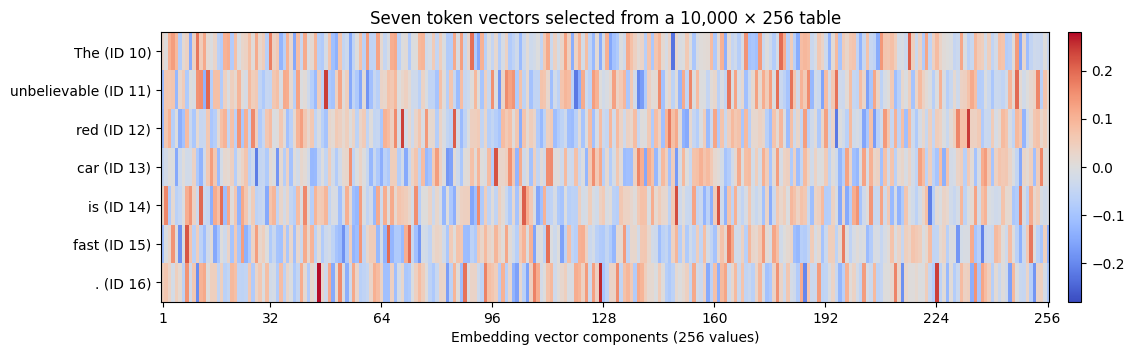

In [33]:
# 한 행이 한 토큰이고, 가로의 256칸이 그 토큰의 벡터 성분이다.
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(embedding_vectors, aspect="auto", cmap="coolwarm", vmin=-0.28, vmax=0.28)
ax.set_yticks(range(len(word_tokens)))
ax.set_yticklabels([f"{token} (ID {tid})" for token, tid in zip(word_tokens, toy_ids)])
ax.set_xticks([0, 31, 63, 95, 127, 159, 191, 223, 255])
ax.set_xticklabels(["1", "32", "64", "96", "128", "160", "192", "224", "256"])
ax.set_xlabel("Embedding vector components (256 values)")
ax.set_title("Seven token vectors selected from a 10,000 × 256 table")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
plt.show()

**그림 읽기:** 각 행이 `The`부터 `.`까지의 토큰 하나를 나타내고, 각 열은 256차원 벡터의 한 성분이다. 색은 숫자의 크기를 나타낼 뿐, **현재 무작위 초기값으로 언어적 의미를 해석할 수는 없다.** 256개 숫자를 직접 계산할 필요는 없다.

### 임베딩 테이블이 학습된다는 것은?

모델이 처음 만들어질 때는 많은 가중치가 초기화된다. 이후 학습에서는 예측 결과가 정답과 얼마나 다른지 확인하고, 오차가 줄어들도록 **임베딩을 포함한 신경망의 가중치를 수정**한다.

예를 들어 다음 토큰 예측을 학습하는 모델은 공통 문장의 앞부분 `The unbelievable red`를 보고 다음 토큰 `car`를 맞히는 연습을 할 수 있다. 이런 연습이 수많은 문장에 반복되면 임베딩 테이블의 값도 달라진다.

**여기서는 훈련을 실행하지 않는다.** 앞의 그림은 테이블의 구조를 보여주고, 실제 학습된 숫자는 뒤에서 저장된 번역 모델을 불러와 확인한다.


### 문장 길이와 패딩

입력 토큰 수는 문장마다 달라질 수 있다. 공통 문장 전체는 7개 토큰으로 `(7, 256)`이고, 그 앞부분 `The unbelievable red car`는 4개 토큰으로 `(4, 256)`이다. 문장 길이를 미리 모두 알 필요는 없다.

서로 다른 길이의 입력을 **같은 크기의 배열로 묶는 경우**, 짧은 입력에 **패딩**(Padding)을 붙일 수 있다. 아래는 같은 문장의 7개·4개 토큰을 하나의 배치로 묶어 길이 7에 맞추는 예제다. **모델의 최대 허용 길이가 7이라는 뜻은 아니다.**


In [34]:
ids_full = toy_ids                          # 7개 토큰
ids_prefix = toy_ids[:4]                    # 같은 문장의 앞부분 4개
PAD_ID = toy_vocab["[PAD]"]                 # ID 0

# 이 배치에서 가장 긴 길이인 7에 맞춤 (모델의 최대 입력 길이와는 다름)
batch_length = max(len(ids_full), len(ids_prefix))
ids_batch = np.array([
    np.pad(ids_full, (0, batch_length - len(ids_full)), constant_values=PAD_ID),
    np.pad(ids_prefix, (0, batch_length - len(ids_prefix)), constant_values=PAD_ID),
], dtype=np.int64)

# 패딩은 실제 토큰이 아님을 알려 주는 마스크: 1=실제, 0=패딩
padding_attention_mask = (ids_batch != PAD_ID).astype(np.int64)
batch_embeddings = embedding_table[ids_batch]

print("배치에 맞춘 길이:", batch_length)
print("패딩된 토큰 ID 배열 (2, 7):\n", ids_batch)
print("패딩 위치를 구별하는 마스크:\n", padding_attention_mask)
print("배치 임베딩 크기:", batch_embeddings.shape)

배치에 맞춘 길이: 7
패딩된 토큰 ID 배열 (2, 7):
 [[10 11 12 13 14 15 16]
 [10 11 12 13  0  0  0]]
패딩 위치를 구별하는 마스크:
 [[1 1 1 1 1 1 1]
 [1 1 1 1 0 0 0]]
배치 임베딩 크기: (2, 7, 256)


패딩 토큰은 원래 문장의 정보가 아니므로 실제 토큰과 구별해야 한다. **패딩 마스크**(Padding Mask)는 각 위치가 실제 토큰인지(1), 패딩인지(0) 표시한다. 패딩과 패딩 마스크는 **서로 다른 역할**을 수행한다.

배치에 맞춘 길이는 모델 자체의 **최대 입력 길이**와 별개다. 최대 512토큰을 허용하는 모델이라고 해서 7개 토큰을 반드시 512개로 채워야 하는 것은 아니다.

### 위치 인코딩: 토큰의 순서를 숫자로 표현하기

임베딩 테이블에서 조회한 벡터만으로는 토큰이 문장의 **몇 번째 위치인지** 알 수 없다. 원래 Transformer는 위치 번호 `p=0, 1, ..., 6`에서 **사인·코사인 값을 계산한 256차원 위치 벡터**를 사용한다.

**$d_{\mathrm{model}}$**은 Transformer 내부에서 한 토큰을 나타내는 벡터의 길이다. 여기서는 256으로 정했다. 원래 방식의 위치 벡터는 **학습하는 가중치가 아니라 정해진 수식으로 계산한 값**이다.

앞의 성분은 $\sin(p)$·$\cos(p)$, 다른 성분은 $\sin(p/10)$·$\cos(p/10)$, 또 다른 성분은 $\sin(p/100)$·$\cos(p/100)$처럼 **위치가 바뀔 때 숫자가 변하는 속도**를 달리한다. 이제 코드에서 실제 숫자들을 비교하자.


In [35]:
# 원래 Transformer의 256차원 사인·코사인 위치 벡터
positions = np.arange(len(word_tokens))[:, None]  # 위치 0~6, (7, 1)
even_dims = np.arange(0, EMBED_DIM, 2)[None, :]
angles = positions / (10000.0 ** (even_dims / EMBED_DIM))

position_encoding = np.zeros((len(word_tokens), EMBED_DIM), dtype=np.float32)
position_encoding[:, 0::2] = np.sin(angles)
position_encoding[:, 1::2] = np.cos(angles)

# 원래 Transformer: 토큰 임베딩을 sqrt(d_model)배 한 뒤 위치 벡터와 더함
d_model = EMBED_DIM
transformer_inputs = embedding_vectors * np.sqrt(d_model) + position_encoding

print("토큰 임베딩:", embedding_vectors.shape)
print("위치 벡터:", position_encoding.shape)
print("Transformer 입력:", transformer_inputs.shape)
print("\n위치 | sin(p) | cos(p) | sin(p/10) | cos(p/10) | sin(p/100)")
for p in (0, 1, 3, 6):
    print(f"{p:4d} | {position_encoding[p, 0]:+.3f} | {position_encoding[p, 1]:+.3f}"
          f" | {position_encoding[p, 64]:+.3f} | {position_encoding[p, 65]:+.3f}"
          f" | {position_encoding[p, 128]:+.3f}")

assert transformer_inputs.shape == (7, 256)
assert np.array_equal(position_encoding[0], np.tile([0, 1], 128))


토큰 임베딩: (7, 256)
위치 벡터: (7, 256)
Transformer 입력: (7, 256)

위치 | sin(p) | cos(p) | sin(p/10) | cos(p/10) | sin(p/100)
   0 | +0.000 | +1.000 | +0.000 | +1.000 | +0.000
   1 | +0.841 | +0.540 | +0.100 | +0.995 | +0.010
   3 | +0.141 | -0.990 | +0.296 | +0.955 | +0.030
   6 | -0.279 | +0.960 | +0.565 | +0.825 | +0.060


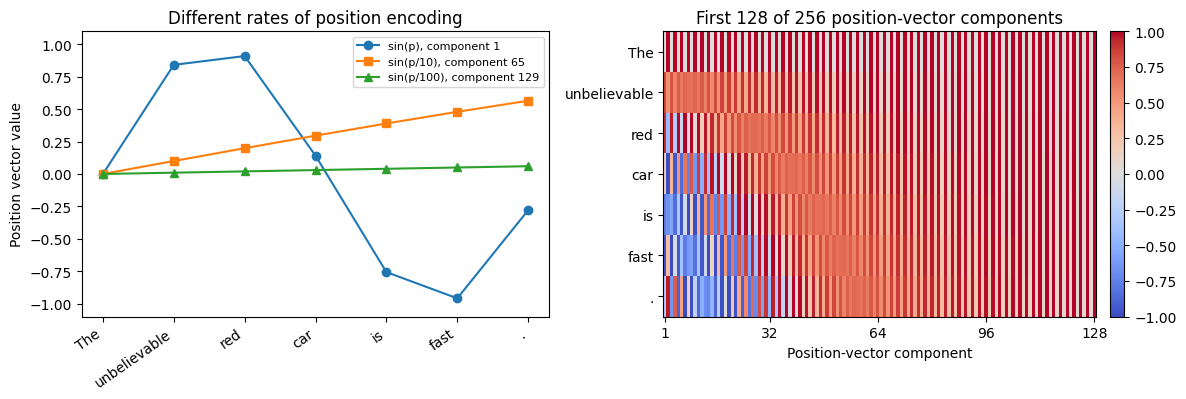

In [36]:
# 위치 번호에 따른 서로 다른 변화 속도를 시각화한다.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
xs = np.arange(len(word_tokens))
axes[0].plot(xs, position_encoding[:, 0], "o-", label="sin(p), component 1")
axes[0].plot(xs, position_encoding[:, 64], "s-", label="sin(p/10), component 65")
axes[0].plot(xs, position_encoding[:, 128], "^-", label="sin(p/100), component 129")
axes[0].set_xticks(xs, word_tokens, rotation=35, ha="right")
axes[0].set_ylim(-1.1, 1.1)
axes[0].set_ylabel("Position vector value")
axes[0].set_title("Different rates of position encoding")
axes[0].legend(fontsize=8)

im = axes[1].imshow(position_encoding[:, :128], aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_yticks(xs, word_tokens)
axes[1].set_xticks([0, 31, 63, 95, 127], ["1", "32", "64", "96", "128"])
axes[1].set_title("First 128 of 256 position-vector components")
axes[1].set_xlabel("Position-vector component")
fig.colorbar(im, ax=axes[1], fraction=0.045, pad=0.03)
plt.tight_layout()
plt.show()


**그래프 읽기:** 세 곡선은 같은 위치 번호를 사용하지만 `p`, `p/10`, `p/100`을 입력하므로 **다른 속도로 변화**한다. 오른쪽은 256개 성분 중 앞의 128개를 색상으로 표시한 것이다. 원래 Transformer의 위치 벡터는 특정 단어의 의미가 아니라 **위치 번호에 의해 결정**된다.

### 이미 학습된 번역 모델의 토크나이저와 임베딩

지금까지는 무작위 값으로 만든 임베딩 표를 사용했다. 이제 다른 사람이 **학습을 마친 번역 모델**을 불러와 저장된 토큰화 규칙과 가중치를 살펴본다.

**사전훈련**(Pretraining)은 일반적으로 다른 과제에 적용하기 전에 많은 자료로 기본적인 패턴을 익히는 학습 단계다. 생성형 언어 모델에서는 다음 토큰 예측이 한 사례다. 반면 실제 번역 모델은 **번역 문장 쌍으로 학습**되는 등 학습 목적이 다를 수 있다. 여기서 중요한 점은 **이미 학습된 가중치를 불러와 사용하며 새로 훈련하지 않는다는 사실**이다.

아래에서는 같은 예문을 **모델이 제공하는 실제 토크나이저**로 나눈다. 따라서 앞의 교육용 ID 10~16과는 다른 ID가 나올 수 있다.


In [37]:
# 영어→스페인어 번역 모델에 포함된 실제 토크나이저
MT_ID = "Helsinki-NLP/opus-mt-en-es"
mt_tokenizer = AutoTokenizer.from_pretrained(MT_ID)
encoded = mt_tokenizer(example_text, return_tensors="pt")

print("같은 원문:", example_text)
print("수업용 단어 토큰 개수:", len(word_tokens))
print("실제 모델의 토큰:", mt_tokenizer.convert_ids_to_tokens(encoded["input_ids"][0]))
print("실제 모델의 토큰 ID:", encoded["input_ids"][0].tolist())
print("실제 입력 ID 배열 모양:", tuple(encoded["input_ids"].shape))
print("토큰에서 텍스트 복원:", mt_tokenizer.decode(encoded["input_ids"][0], skip_special_tokens=True))

같은 원문: The unbelievable red car is fast.
수업용 단어 토큰 개수: 7
실제 모델의 토큰: ['▁The', '▁unbelievable', '▁red', '▁car', '▁is', '▁fast', '.', '</s>']
실제 모델의 토큰 ID: [42, 41834, 1203, 785, 31, 4626, 3, 0]
실제 입력 ID 배열 모양: (1, 8)
토큰에서 텍스트 복원: The unbelievable red car is fast.


실제 모델은 자체 어휘집과 토큰 ID를 사용한다. 아래 코드로 번역 모델이 저장한 **임베딩 테이블**에서 이번 문장에 해당하는 행들을 가져와 모양을 확인한다. 이것은 **가중치를 조회하는 작업**이며 학습은 아니다.


In [38]:
# 번역 모델은 이 절에서 한 번만 불러오고 뒤의 번역 실습에서도 재사용한다.
mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_ID)
mt_model.eval()

# 모델의 표준 입력 임베딩 계층을 사용하여 토큰 ID에 해당하는 행을 조회한다.
embedding_layer = mt_model.get_input_embeddings()
with torch.inference_mode():
    pretrained_embeddings = embedding_layer(encoded["input_ids"])

print("실제 모델의 임베딩 테이블:", tuple(embedding_layer.weight.shape))
print("실제 모델의 입력 ID 배열:", tuple(encoded["input_ids"].shape))
print("실제 입력에서 조회한 임베딩:", tuple(pretrained_embeddings.shape))
print("첫 토큰 벡터의 앞 8개 값:", pretrained_embeddings[0, 0, :8].tolist())

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

실제 모델의 임베딩 테이블: (65001, 512)
실제 모델의 입력 ID 배열: (1, 8)
실제 입력에서 조회한 임베딩: (1, 8, 512)
첫 토큰 벡터의 앞 8개 값: [0.005900266580283642, 0.014783626422286034, -0.01451471820473671, 0.01198298018425703, 0.006228791084140539, -0.015497134998440742, 0.0030602910555899143, -0.0037253559567034245]


**정리:** 교육용 임베딩 표는 구조를 관찰하기 위해 무작위 값으로 초기화했다. 실제 번역 모델에 저장된 임베딩은 **학습 과정에서 이미 조정된 가중치**다. 두 경우 모두 토큰 ID로 필요한 행을 조회하지만 **어휘집 크기와 임베딩 차원은 모델에 따라 다르다.**

**확인 질문:** 어휘집을 구축하는 과정을 설명할 수 있는가? 임베딩 테이블 모양 `(10000, 256)`과 문장 입력 모양 `(7, 256)`의 차이는 무엇인가? 위치 벡터 `sin(p)`와 `sin(p/10)`의 변화는 어떻게 다른가? 패딩과 모델의 최대 길이는 왜 구별해야 하는가?


---
## Self-Attention과 Q·K·V: 같은 문장으로 관계 살펴보기

앞에서 사용한 동일한 **7개 토큰**, 즉 `The unbelievable red car is fast.`를 계속 사용한다.

- Q(Query): 현재 `car`가 **어떤 정보를 찾는가**
- K(Key): 각 토큰이 **어떤 정보를 제공할 수 있는가**
- V(Value): 관련성이 계산된 뒤 **실제로 더할 정보**

**순서:** Q·K 관련성 → Softmax로 가중치 → V의 가중합. 이번에도 값을 **교육용으로 미리 설정**하며 모델은 학습하지 않는다.


### 먼저 2차원 숫자로 원리 확인

7개 중 `red`, `car`, `fast`라는 **세 토큰만 잠깐 골라** `car`가 어떤 토큰을 참고하는지 계산해 보자. 이것은 **같은 원문에서 세 개만 뽑은 계산 예제**로, 다른 문장을 새로 도입한 것이 아니다.


In [39]:
# 세 토큰은 모두 공통 문장에 등장한다.
chosen=['red','car','fast']
query=np.array([1.0,0.0])
keys=np.array([[2.0,0.0],[0.5,0.5],[1.8,0.2]])
values=np.array([[1.0,0.0],[0.5,0.5],[0.0,1.0]])

scores=keys@query/np.sqrt(2)
z=np.exp(scores-scores.max())
weights=z/z.sum()
context=weights@values
for name,wt in zip(chosen,weights):
    print(f'{name:>5}: {wt:.3f}')
print('가중치의 합:',round(float(weights.sum()),3))
print('V의 가중합(2차원 문맥 벡터):',context.round(3))


  red: 0.452
  car: 0.156
 fast: 0.392
가중치의 합: 1.0
V의 가중합(2차원 문맥 벡터): [0.53 0.47]


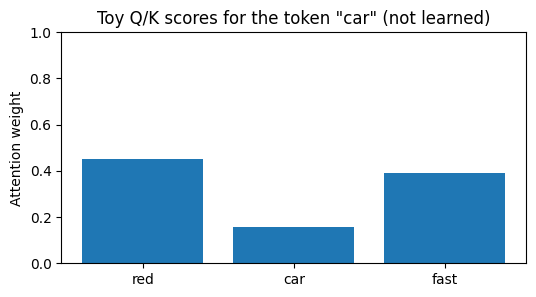

In [40]:
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(chosen,weights)
ax.set_ylim(0,1)
ax.set_ylabel('Attention weight')
ax.set_title('Toy Q/K scores for the token "car" (not learned)')
plt.show()


**막대그래프 해석:** `car`의 Q에 대해 `red`와 `fast`의 K가 얼마나 관련되는지에 따라 가중치가 달라진다. 이 가중치를 **각 토큰의 V**에 곱해 합산한다. 숫자는 원리를 위한 예제이고, **언어 의미가 학습된 결과가 아니다.**

### 같은 일곱 토큰을 256차원으로 확장

앞에서 사용한 **수업용 ID 10~16**에 대응하는 **7개 토큰**을 사용한다. 처음에는 256차원 배열을 만들지만, 쉽게 확인하도록 **몇 개 좌표에만 교육용 특징값**을 설정한다. `car`가 `red`와 `fast`를 상대적으로 많이 참고하도록 Q와 K를 고른다.


In [41]:
attn_tokens=word_tokens                         # 7개 토큰(공통 예문)
d_model=256
X=np.zeros((len(attn_tokens),d_model),dtype=np.float32)
X[2,2]=1.0  # red
X[3,3]=1.0  # car
X[5,5]=1.0  # fast

# 실제로는 학습된 선형 변환들이지만, 여기서는 설명용 값으로 직접 설정.
W_Q=np.zeros((d_model,d_model),dtype=np.float32)
W_K=np.zeros((d_model,d_model),dtype=np.float32)
W_V=np.eye(d_model,dtype=np.float32)
W_Q[3,2]=32.0       # car가 red를 참고하도록 설계
W_Q[3,5]=32.0       # car가 fast를 참고하도록 설계
W_Q[3,3]=16.0       # car 자신도 조금 참고
W_K[2,2]=W_K[3,3]=W_K[5,5]=1.0
Q=X@W_Q
K=X@W_K
V=X@W_V
print('수업용 토큰 ID:',toy_ids.tolist())
print('입력 X:',X.shape,'Q,K,V:',Q.shape,K.shape,V.shape)


수업용 토큰 ID: [10, 11, 12, 13, 14, 15, 16]
입력 X: (7, 256) Q,K,V: (7, 256) (7, 256) (7, 256)


### 모든 토큰의 Attention 가중치를 7×7로 보기

각 행이 **현재 토큰**(Query)이고 각 열이 **참고되는 토큰**(Key)이다. 행의 합은 1이며, 이를 V `(7, 256)`에 적용하면 문맥 벡터 `(7, 256)`이 된다.


In [42]:
score_matrix=(Q@K.T)/np.sqrt(d_model)
z=np.exp(score_matrix-score_matrix.max(axis=1,keepdims=True))
attention_weights=z/z.sum(axis=1,keepdims=True)
context_vectors=attention_weights@V

print('Attention 가중치:',attention_weights.shape)
print('V의 가중합 결과:',context_vectors.shape)
print('car 토큰이 참고하는 가중치 (정확한 값):')
for token,weight in zip(attn_tokens,attention_weights[3]):
    print(f'  {token:>13}: {weight:.3f}')
print('가중치 합:',round(float(attention_weights[3].sum()),3))


Attention 가중치: (7, 7)
V의 가중합 결과: (7, 256)
car 토큰이 참고하는 가중치 (정확한 값):
            The: 0.047
   unbelievable: 0.047
            red: 0.344
            car: 0.126
             is: 0.047
           fast: 0.344
              .: 0.047
가중치 합: 1.0


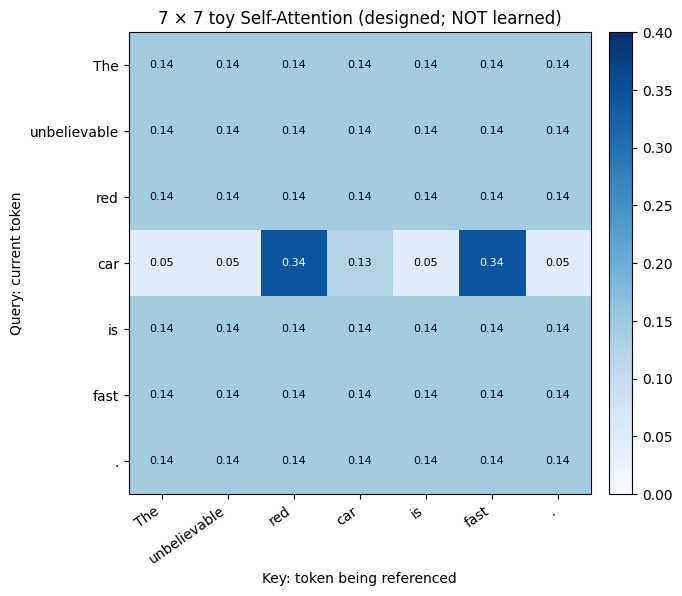

In [43]:
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(attention_weights,cmap='Blues',vmin=0,vmax=.4)
ax.set_xticks(range(len(attn_tokens)),attn_tokens,rotation=35,ha='right')
ax.set_yticks(range(len(attn_tokens)),attn_tokens)
ax.set_xlabel('Key: token being referenced')
ax.set_ylabel('Query: current token')
ax.set_title('7 × 7 toy Self-Attention (designed; NOT learned)')
for i in range(len(attn_tokens)):
    for j in range(len(attn_tokens)):
        w=attention_weights[i,j]
        ax.text(j,i,f'{w:.2f}',ha='center',va='center',fontsize=8,
                color=('white' if w>.26 else 'black'))
fig.colorbar(im,ax=ax,fraction=.044,pad=.03)
plt.show()


**히트맵 읽기:** `car` 행에서 `red`, `fast`가 상대적으로 진하다. 그렇게 되도록 **Q·K를 직접 설계**했기 때문이다. 이는 학습된 모델의 실제 Attention 패턴을 보여주는 것이 아니다.

**차원에 주목하자:** 토큰이 7개이므로 Attention 가중치 표는 `(7, 7)`이다. 이 가중치를 V `(7, 256)`에 적용해 얻는 문맥 표현은 `(7, 256)`이다.

**Attention 핵심 정리:** **Q·K로 어느 토큰을 얼마나 참고할지 정하고, 그 가중치로 V를 합친다.** 다음에는 이 원리를 여러 Head로 확장하고, Encoder와 Decoder에서 참고 가능한 범위를 비교해 본다.

### Multi-Head Attention: 256차원 입력에서 4개 Head 만들기

앞에서 확인한 것은 **한 개 Head의 단순화된 Self-Attention**이었다. 이제 Theory의 교육용 설정과 같이 **토큰 표현 256차원, Head 4개, 각 Head 64차원**을 사용해 보자.

- 네 Head는 **각각 전체 입력 `(7, 256)`을 받는다.** 입력을 앞에서부터 64차원씩 잘라 나누는 것이 아니다.
- Head마다 서로 다른 Q·K·V 선형변환을 적용한 뒤 Attention을 계산한다.
- 네 Head의 결과 `(7, 64)`를 **가로로 연결**하면 `(7, 256)`이 된다.
- 원래 Transformer는 연결한 결과에 **학습 가능한 출력 선형변환**을 한 번 더 적용한다. 아래에서는 그 연산의 모양만 확인한다.

아래 가중치들은 임의로 만든 **무작위 값**이며 실제 언어적 관계를 학습한 결과가 아니다. 모델 훈련은 수행하지 않는다.

In [44]:
# 수업용 Multi-Head Attention: 전체 256차원 입력을 Head마다 서로 다르게 변환
NUM_HEADS = 4
HEAD_DIM = 64
rng_heads = np.random.default_rng(2026)
X_heads = transformer_inputs.astype(np.float32)   # 앞에서 계산한 (7, 256)

head_outputs = []
for h in range(NUM_HEADS):
    # 실제 모델에서는 이 행렬들이 학습되는 가중치이다. 여기서는 임의값을 사용한다.
    Wq_h = rng_heads.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, HEAD_DIM))
    Wk_h = rng_heads.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, HEAD_DIM))
    Wv_h = rng_heads.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, HEAD_DIM))
    q_h, k_h, v_h = X_heads @ Wq_h, X_heads @ Wk_h, X_heads @ Wv_h

    head_scores = (q_h @ k_h.T) / np.sqrt(HEAD_DIM)       # (7, 7)
    head_exp = np.exp(head_scores - head_scores.max(axis=1, keepdims=True))
    head_weights = head_exp / head_exp.sum(axis=1, keepdims=True)
    head_out = head_weights @ v_h                         # (7, 64)
    head_outputs.append(head_out)
    print(f"Head {h + 1}: 입력 {X_heads.shape} → Q/K/V {q_h.shape} → 출력 {head_out.shape}")

concatenated = np.concatenate(head_outputs, axis=1)       # (7, 256)
W_output = rng_heads.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, EMBED_DIM))
multihead_output = concatenated @ W_output                 # (7, 256)

print("연결(Concatenate):", concatenated.shape)
print("출력 선형변환 후:", multihead_output.shape)
assert len(head_outputs) == 4
assert all(h.shape == (7, 64) for h in head_outputs)
assert concatenated.shape == multihead_output.shape == (7, 256)

Head 1: 입력 (7, 256) → Q/K/V (7, 64) → 출력 (7, 64)
Head 2: 입력 (7, 256) → Q/K/V (7, 64) → 출력 (7, 64)
Head 3: 입력 (7, 256) → Q/K/V (7, 64) → 출력 (7, 64)
Head 4: 입력 (7, 256) → Q/K/V (7, 64) → 출력 (7, 64)
연결(Concatenate): (7, 256)
출력 선형변환 후: (7, 256)


**결과 해석:** `(7, 64)`는 **토큰 7개의 각각에 64개의 숫자가 생겼다**는 뜻이다. 네 Head의 결과를 연결해도 토큰 수 7개는 변하지 않는다. 연결 후 출력 선형변환은 Head가 추출한 특징을 다시 조합한다.

**생각해 보기:** (1) Head 하나의 입력은 왜 `(7, 64)`가 아니라 `(7, 256)`인가? (2) Head를 네 개 사용해도 Attention 가중치 행렬이 Head마다 `(7, 7)`인 이유는 무엇인가?

참고로 **원래 Transformer 기본 모델**은 토큰 표현 **512차원, Head 8개, Head당 64차원**이었다. Head마다 차원을 반드시 동일하게 해야 하는 것은 아니지만, 표준 구현에서는 계산 효율을 위해 같은 차원을 주로 사용한다.

---
## Encoder와 Decoder의 세 가지 Attention 비교

지금까지의 Self-Attention은 같은 문장 속 토큰들을 참고했다. 원래 Transformer는 **Encoder에서 입력 전체를 참고하는 Self-Attention**, **Decoder에서 미래를 가리는 Self-Attention**, 그리고 **Decoder가 Encoder 출력을 참고하는 Cross-Attention**을 사용한다.

| 종류 | Q의 출처 | K·V의 출처 | 어떤 위치를 참고할 수 있을까? |
|---|---|---|---|
| **Encoder Self-Attention** | 영어 입력 표현 | 같은 영어 입력 표현 | 입력 문장의 앞뒤 전체 |
| **Decoder Masked Self-Attention** | 스페인어 출력 쪽 표현 | 같은 출력 쪽 표현 | 현재 위치와 이전 위치 |
| **Cross-Attention** | Decoder 표현 | Encoder 출력 | 영어 입력 문장 전체 |

앞에서 만든 `(7, 7)` 가중치는 **영어 7개 토큰의 Encoder Self-Attention**에 해당하는 모양이다. 이제 Decoder에서 무엇을 가리는지 확인한다.

### Decoder의 Teacher Forcing: 정답을 한 칸 이동해 입력하기

새로운 번역문을 생성할 때는 다음 토큰을 **하나씩** 예측한다. 하지만 **훈련 데이터에는 스페인어 정답 문장도 이미 있으므로**, 훈련에서는 정답 토큰들을 **한 칸 오른쪽으로 이동시켜 Decoder 입력**으로 사용한다. 이를 **Teacher Forcing**이라고 한다.

Theory의 스페인어 번역 예시 `El increíble coche rojo ...`에서 **앞의 네 토큰만** 가져오자. 아래 코드는 **훈련 데이터를 구성하는 방식만 보여 주며, 모델을 훈련하거나 번역을 예측하지 않는다.**

In [45]:
# 교육용 훈련 데이터 배열: 정답 토큰을 한 위치 오른쪽으로 이동
spanish_targets = ["El", "increíble", "coche", "rojo"]
decoder_input_tokens = ["[start]"] + spanish_targets[:-1]

print("Decoder 입력:", decoder_input_tokens)
print("예측 정답   :", spanish_targets)
print("\n위치별로 모델이 풀어야 할 다음 토큰 예측 문제:")
for position, target in enumerate(spanish_targets):
    visible_prefix = " ".join(decoder_input_tokens[:position + 1])
    print(f"위치 {position}: {visible_prefix:<27} → {target}")

assert len(decoder_input_tokens) == len(spanish_targets) == 4

Decoder 입력: ['[start]', 'El', 'increíble', 'coche']
예측 정답   : ['El', 'increíble', 'coche', 'rojo']

위치별로 모델이 풀어야 할 다음 토큰 예측 문제:
위치 0: [start]                     → El
위치 1: [start] El                  → increíble
위치 2: [start] El increíble        → coche
위치 3: [start] El increíble coche  → rojo


**왜 정답을 입력하면서도 예측을 학습할 수 있을까?** 각 위치는 **미래 정답 토큰을 보지 못하기 때문**이다. 실제로는 네 위치를 한 번에 계산하되, 첫 위치가 뒤에 입력된 `El`이나 `coche`를 미리 참고하지 못하도록 제한해야 한다. 바로 이때 **Causal Mask**를 사용한다.

### Causal Mask: 입력된 토큰 중 미래 위치를 가린다

**Mask가 토큰을 삭제하는 것은 아니다.** Q·K로 계산한 Attention 점수에서 **미래 위치를 차단**하여, Softmax 이후 해당 위치의 가중치가 **0**이 되게 한다. 행은 정보를 요청하는 **Q 위치**, 열은 참고할 **K 위치**이다.

아래의 점수는 작동 원리를 확인하기 위해 임의로 설정했다. 훈련된 모델의 Attention 결과가 아니다.

Causal Mask (1=참고 가능, 0=미래 차단):
 [[1 0 0 0]
 [1 1 0 0]
 [1 1 1 0]
 [1 1 1 1]]
Softmax 이후 Attention 가중치:
 [[1.    0.    0.    0.   ]
 [0.574 0.426 0.    0.   ]
 [0.224 0.369 0.408 0.   ]
 [0.171 0.255 0.344 0.231]]
각 행의 합: [1. 1. 1. 1.]


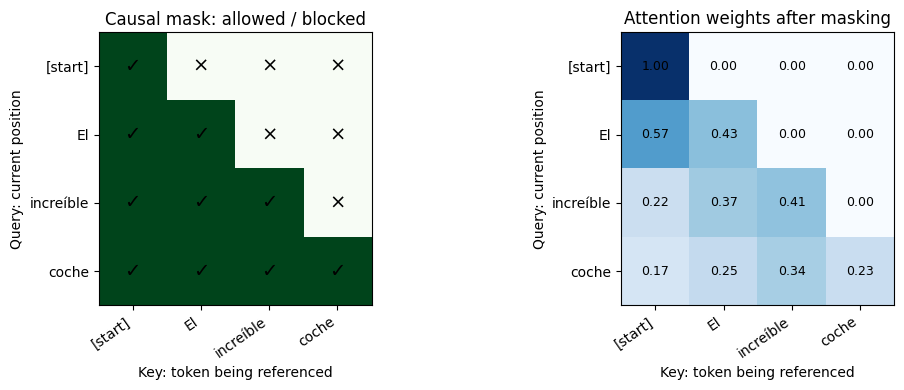

In [46]:
# ✓ 현재/이전 위치는 참고 가능, × 미래 위치는 차단
T = len(decoder_input_tokens)
causal_mask = np.tril(np.ones((T, T), dtype=bool))

# 설명용 점수: 첫 위치에서는 미래 토큰의 점수가 높아도 차단되어야 한다.
toy_decoder_scores = np.array([
    [0.1, 2.0, 3.0, 4.0],
    [0.6, 0.3, 2.0, 3.0],
    [0.2, 0.7, 0.8, 3.0],
    [0.1, 0.5, 0.8, 0.4],
])
masked_scores = np.where(causal_mask, toy_decoder_scores, -np.inf)
e = np.exp(masked_scores - masked_scores.max(axis=1, keepdims=True))
masked_attention = e / e.sum(axis=1, keepdims=True)

print("Causal Mask (1=참고 가능, 0=미래 차단):\n", causal_mask.astype(int))
print("Softmax 이후 Attention 가중치:\n", np.round(masked_attention, 3))
print("각 행의 합:", np.round(masked_attention.sum(axis=1), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(causal_mask.astype(int), cmap="Greens", vmin=0, vmax=1)
axes[0].set_title("Causal mask: allowed / blocked")
axes[1].imshow(masked_attention, cmap="Blues", vmin=0, vmax=1)
axes[1].set_title("Attention weights after masking")
for ax in axes:
    ax.set_xticks(range(T), decoder_input_tokens, rotation=35, ha="right")
    ax.set_yticks(range(T), decoder_input_tokens)
    ax.set_xlabel("Key: token being referenced")
    ax.set_ylabel("Query: current position")
for i in range(T):
    for j in range(T):
        axes[0].text(j, i, "✓" if causal_mask[i, j] else "×",
                     ha="center", va="center", fontsize=14)
        axes[1].text(j, i, f"{masked_attention[i, j]:.2f}",
                     ha="center", va="center", fontsize=9)
plt.tight_layout()
plt.show()

assert np.allclose(masked_attention.sum(axis=1), 1)
assert np.all(masked_attention[np.triu_indices(T, k=1)] == 0)

**그림 읽기:** 첫 번째 행 `[start]`는 첫 번째 열만 참고한다. 뒤쪽 `El`, `increíble`, `coche`는 **훈련 입력에 이미 존재하더라도** 이 위치에서는 Attention 가중치가 0이다. 이 제한 덕분에 **네 위치의 다음 토큰 예측을 병렬로 계산**해도 미래 정답을 미리 보지 않게 된다.

**훈련과 실제 생성의 차이**

| 구분 | 훈련 | 새로운 문장 번역(추론) |
|---|---|---|
| Decoder 입력 | 이전 **정답** 토큰 | 이전에 **생성한** 토큰 |
| 다음 토큰 예측 | 여러 위치에서 **병렬** 계산 가능 | 보통 **한 토큰씩** 생성 |
| Causal Mask | 입력에 있는 미래 정답의 참조를 막음 | 마지막 위치에는 아직 미래 토큰이 없지만 구현상 사용 가능 |
| 목적 | 예측과 정답을 비교해 **가중치를 학습** | 학습된 가중치로 **처음 보는 번역문을 생성** |

Teacher Forcing을 사용하는 이유는 새로운 번역문을 **한꺼번에 생성하기 위해서가 아니다.** 정답 문장의 여러 위치에서 **다음 토큰을 예측하는 능력을 효율적으로 학습**하기 위해서다. 이번 Lab에서는 그 구조만 확인하며 가중치를 바꾸지 않는다.

**패딩 마스크와도 구별하자.** Padding Mask는 길이를 맞추기 위해 붙인 채움 위치를 무시하고, Causal Mask는 미래 위치를 차단한다. 실제 모델에서는 둘을 함께 사용할 수 있다.

### Cross-Attention: Decoder는 영어 입력 전체를 참고한다

Decoder의 **Masked Self-Attention**과 달리 **Cross-Attention**에서는 Q가 **Decoder 쪽 4개 위치**에서, K·V가 **Encoder 쪽 영어 7개 토큰**에서 나온다. 그래서 Attention 가중치 행렬은 정사각형이 아니라 **`(4, 7)`**이다.

아래 예시는 이를 **한 Head(64차원)**에서 계산한다. Decoder 입력 표현은 설명용 무작위 배열이고, Encoder 표현은 앞에서 만든 공통 영어 문장의 `(7, 256)` 배열을 사용한다. **학습된 번역 모델의 실제 Attention을 추출한 것은 아니다.**

Decoder의 Q: (4, 64)
Encoder의 K/V: (7, 64) (7, 64)
Cross-Attention 가중치: (4, 7)
한 Head의 Cross-Attention 출력: (4, 64)


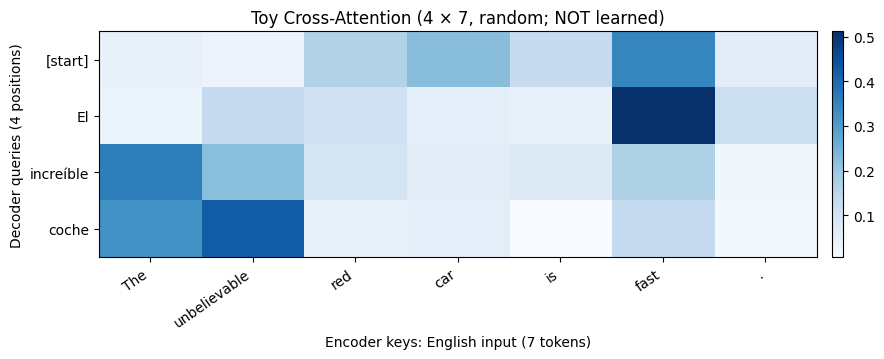

In [47]:
# Cross-Attention: Q는 Decoder, K/V는 Encoder에서 만든다.
rng_cross = np.random.default_rng(9)
encoder_repr = transformer_inputs.astype(np.float64)                  # (7, 256)
decoder_repr = rng_cross.normal(size=(len(decoder_input_tokens), EMBED_DIM))  # (4, 256), 설명용

Wq_cross = rng_cross.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, HEAD_DIM))
Wk_cross = rng_cross.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, HEAD_DIM))
Wv_cross = rng_cross.normal(0, 1 / np.sqrt(EMBED_DIM), (EMBED_DIM, HEAD_DIM))
Q_cross = decoder_repr @ Wq_cross                            # (4, 64)
K_cross = encoder_repr @ Wk_cross                            # (7, 64)
V_cross = encoder_repr @ Wv_cross                            # (7, 64)

cross_scores = (Q_cross @ K_cross.T) / np.sqrt(HEAD_DIM)      # (4, 7)
cross_exp = np.exp(cross_scores - cross_scores.max(axis=1, keepdims=True))
cross_weights = cross_exp / cross_exp.sum(axis=1, keepdims=True)
cross_output = cross_weights @ V_cross                       # (4, 64)

print("Decoder의 Q:", Q_cross.shape)
print("Encoder의 K/V:", K_cross.shape, V_cross.shape)
print("Cross-Attention 가중치:", cross_weights.shape)
print("한 Head의 Cross-Attention 출력:", cross_output.shape)

fig, ax = plt.subplots(figsize=(9, 3.7))
im = ax.imshow(cross_weights, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(word_tokens)), word_tokens, rotation=35, ha="right")
ax.set_yticks(range(len(decoder_input_tokens)), decoder_input_tokens)
ax.set_xlabel("Encoder keys: English input (7 tokens)")
ax.set_ylabel("Decoder queries (4 positions)")
ax.set_title("Toy Cross-Attention (4 × 7, random; NOT learned)")
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
plt.tight_layout()
plt.show()

assert (Q_cross.shape, K_cross.shape, V_cross.shape) == ((4, 64), (7, 64), (7, 64))
assert cross_weights.shape == (4, 7)
assert cross_output.shape == (4, 64)

**그림 읽기:** 세로축은 **스페인어 쪽 4개 위치**, 가로축은 **영어 입력의 7개 토큰**이다. 각 스페인어 위치는 영어 입력 전체를 참고할 수 있다(패딩이 있다면 그 위치는 제외). 그림의 진한 칸은 **무작위 가중치로 만들어진 값**일 뿐 번역상의 의미를 나타내지 않는다.

| Attention 종류 | Q 토큰 수 | K·V 토큰 수 | 한 Head의 가중치 모양 |
|---|---:|---:|---|
| Encoder Self-Attention | 영어 7개 | 영어 7개 | `(7, 7)` |
| Decoder Masked Self-Attention | 스페인어 4개 | 스페인어 4개 | `(4, 4)` — 미래 차단 |
| Cross-Attention | 스페인어 4개 | 영어 7개 | **`(4, 7)`** |

**생각해 보기:** Cross-Attention에서는 왜 Decoder의 미래 출력은 가리지만 Encoder의 영어 입력 전체를 참고하는 것이 가능할까?

---
## Encoder–Decoder 활용: 영어 → 스페인어 번역

**번역 모델을 직접 훈련하지 않는다.** 사전훈련된 Encoder–Decoder 계열의 Transformer를 가져와 새 영어 문장들을 번역한다.

원리: **영어 입력 → Encoder 문맥 표현 → Decoder가 다음 스페인어 토큰을 반복 생성**

이전에 불러온 `mt_tokenizer`와 `mt_model`을 재사용한다.


In [48]:
# 영어→스페인어 번역 예제: 공통 문장을 포함하여 비교
english_sentences = [
    "How is the weather today?",
    "You are welcome.",
    "The unbelievable red car is fast.",
    "I like reading books.",
]

inputs = mt_tokenizer(
    english_sentences,
    return_tensors="pt",
    padding=True,
    truncation=True,
)

# 모델 가중치를 바꾸지 않고 번역 결과만 생성
with torch.inference_mode():
    output_ids = mt_model.generate(**inputs, max_new_tokens=60)

spanish_sentences = mt_tokenizer.batch_decode(
    output_ids, skip_special_tokens=True
)

for en, es in zip(english_sentences, spanish_sentences):
    print("EN:", en)
    print("ES:", es)
    print("-" * 44)


[transformers] Both `max_new_tokens` (=60) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


EN: How is the weather today?
ES: ¿Cómo está el clima hoy?
--------------------------------------------
EN: You are welcome.
ES: De nada.
--------------------------------------------
EN: The unbelievable red car is fast.
ES: El coche rojo increíble es rápido.
--------------------------------------------
EN: I like reading books.
ES: Me gusta leer libros.
--------------------------------------------


### 실제 번역 모델이 생성한 토큰을 순서대로 관찰하기

앞의 Teacher Forcing 코드는 **훈련에서 정답을 입력하는 방법**을 보여 주었다. 반면 방금 실행한 `mt_model.generate()`는 **정답 스페인어 문장을 받지 않고**, 모델이 앞서 생성한 토큰을 바탕으로 **새 토큰을 하나씩** 선택한다.

다음 코드는 방금 생성된 결과 중 공통 영어 문장 `The unbelievable red car is fast.`의 **실제 출력 토큰 ID를 생성 순서대로 펼쳐 보인다. **생성 과정을 다시 실행하는 코드는 아니며**, `generate()`가 반환한 결과를 단계별로 확인하는 것이다.** 여러 모델의 토크나이저는 단어가 아니라 **부분단어 토큰**을 사용하므로, 표의 한 행이 항상 한 단어인 것은 아니다. 특별 토큰(시작·종료·패딩 등)은 관찰 표에서 제외한다.

In [49]:
# 앞의 generate()가 만든 토큰 시퀀스를 한 토큰씩 해석해 보기
example_index = english_sentences.index(example_text)
generated_token_ids = output_ids[example_index].tolist()
special_token_ids = set(mt_tokenizer.all_special_ids)

visible_token_ids = []
print("영어 입력:", example_text)
print("순서 | 토큰 ID | 모델의 부분단어 토큰 | 현재까지 생성된 스페인어")
for token_id in generated_token_ids:
    if token_id in special_token_ids:
        continue  # 학습된 모델의 시작/종료/패딩 토큰은 화면에서 제외
    visible_token_ids.append(token_id)
    subword_piece = mt_tokenizer.convert_ids_to_tokens(token_id)
    partial_translation = mt_tokenizer.decode(
        visible_token_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    print(f"{len(visible_token_ids):>4} | {token_id:>7} | {subword_piece!r:<20} | {partial_translation}")

print("\n최종 번역:", spanish_sentences[example_index])
print("(이 표는 generate() 결과를 순서대로 보여 준 것으로, 추가 훈련은 하지 않았습니다.)")

영어 입력: The unbelievable red car is fast.
순서 | 토큰 ID | 모델의 부분단어 토큰 | 현재까지 생성된 스페인어
   1 |      54 | '▁El'                | El
   2 |    2638 | '▁coche'             | El coche
   3 |    9169 | '▁rojo'              | El coche rojo
   4 |    8545 | '▁increíble'         | El coche rojo increíble
   5 |      43 | '▁es'                | El coche rojo increíble es
   6 |    3048 | '▁rápido'            | El coche rojo increíble es rápido
   7 |       3 | '.'                  | El coche rojo increíble es rápido.

최종 번역: El coche rojo increíble es rápido.
(이 표는 generate() 결과를 순서대로 보여 준 것으로, 추가 훈련은 하지 않았습니다.)


### 관찰 및 해석

1. 공통 영어 문장의 `red car`가 스페인어 번역에서도 같은 순서로 나타나는가?
2. **실제 생성 토큰 표**에서 토큰 하나가 반드시 단어 하나와 같은가? 결과를 근거로 설명해 보자.
3. 번역 모델의 Decoder는 **Causal Mask**로 무엇을 제한하고, **Cross-Attention**으로 무엇을 참고하는가?
4. `You are welcome.`이 문맥에 따라 다르게 해석될 수 있는 이유는 무엇일까? **현재 번역 결과 한 개만으로 번역이 하나라고 결론 내릴 수는 없다.**

**추가 실험:** `english_sentences`에 `You are welcome to join us.`를 추가하여 앞의 **번역 실행 셀과 토큰 관찰 셀**을 다시 실행해 보자. 같은 영어 표현도 문맥에 따라 번역이 달라지는지 관찰한다. **모델을 새로 학습할 필요는 없다.**

### 세 가지 Transformer 구조의 현재 활용

| 구조 | 대표 활용 | 이 실습에서 |
|---|---|---|
| **Encoder-only** (BERT 등) | 텍스트 분류·의미 검색·임베딩 | **개념만 소개** — 모델 실행 없음 |
| **Encoder–Decoder** (MarianMT 등) | 번역·요약·음성 인식 | **영어→스페인어 번역** |
| **Decoder-only** (GPT 계열 등) | 글쓰기·질의응답·코드 생성 | **이어쓰기·질의응답** |

예를 들어 Encoder-only 기반 임베딩 모델은 `반려견 관리`와 `강아지 돌보기`처럼 표현이 달라도 의미가 비슷한 문서를 찾는 데 활용할 수 있다. **이 구분은 대표적 용도일 뿐**, Decoder-only 모델도 번역 등을 수행할 수 있다.



### 번역 모델에서 LLM으로 연결하기

방금 사용한 모델은 **Encoder–Decoder Transformer**다. 영어 문장을 Encoder가 처리하고, Decoder는 그 내용을 참고하여 스페인어 번역을 생성했다.

이제 사용할 모델은 **Decoder-only Transformer 기반의 소형 언어 모델**이다. 별도의 Encoder나 Cross-Attention 없이 **프롬프트와 이미 생성한 토큰을 한 줄의 시퀀스로 처리**하며, 다음 토큰을 반복 예측한다.

| 이번 Lab의 모델 | 모델 구조 | 무엇을 확인할까? |
|---|---|---|
| 영어→스페인어 번역 모델 | Encoder–Decoder | 입력 문장을 참고한 번역문 생성 |
| 소형 지시문 응답 언어 모델 | Decoder-only | 프롬프트를 이어 쓰고 질문에 답하는 과정 |

두 모델 모두 **이미 학습된 가중치를 불러와 사용**한다. 여기서 *LLM*이라는 말은 단순히 Decoder라는 블록 자체를 뜻하지 않고, **많은 데이터로 학습된 언어 모델**을 가리킨다. 이번 실습의 소형 모델은 이 원리를 관찰하기 위한 교육용 예제이며, 대형 상용 LLM의 성능을 대표하지 않는다.


---
## Decoder-only: 다음 토큰을 예측하고 문장을 생성하기

이번에는 Encoder가 따로 없는 **Decoder-only** 모델을 사용한다. 입력 프롬프트를 보고 다음 토큰의 확률을 계산한 다음, 토큰을 하나씩 추가한다.

빠른 실습을 위해 **작은 모델**을 사용한다. 따라서 출력이 어색하거나 틀릴 수 있다. 여기서 보는 것은 답변 품질이 아니라 **어떻게 텍스트를 생성하는지**이다.


In [50]:
LM_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"
lm_tokenizer = AutoTokenizer.from_pretrained(LM_ID)
lm_model = AutoModelForCausalLM.from_pretrained(LM_ID)
lm_model.eval()

print("사용하는 Decoder-only 모델:", LM_ID)


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

사용하는 Decoder-only 모델: HuggingFaceTB/SmolLM2-135M-Instruct


### 다음 토큰 후보의 확률 확인

모델에 문장을 넣고 **마지막 위치**에서 다음 토큰의 확률을 확인한다. 예제에서는 가장 가능성이 높다고 예측한 상위 5개 토큰을 살펴본다.

실제 모델의 확률이므로 교재의 가상 예시와 일치하지 않을 수 있다.


In [51]:
prompt = "The capital of France is"
encoded_lm = lm_tokenizer(prompt, return_tensors="pt")

with torch.inference_mode():
    logits = lm_model(**encoded_lm).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)

values, indices = torch.topk(probs, k=5)
print("입력:", prompt)
print("다음 토큰 후보:")
for token_id, prob in zip(indices.tolist(), values.tolist()):
    token = lm_tokenizer.decode([token_id])
    print(f"  {token!r:<18} 확률: {prob:.3f}")


입력: The capital of France is
다음 토큰 후보:
  ' Paris'           확률: 0.445
  ' the'             확률: 0.270
  ' located'         확률: 0.088
  ' called'          확률: 0.020
  ' Le'              확률: 0.016


### 활용: 텍스트 이어쓰기와 간단한 질의응답

모델에는 텍스트를 이어 쓰라는 **지시문** 또는 질문을 넣을 수 있다. 두 작업 모두 내부적으로는 다음 토큰 생성이 반복된다.

아래 함수는 '질문/지시문 → 생성 결과'를 간단히 확인하기 위한 것이다. **Chat Template**은 역할(user/assistant)을 모델이 이해하는 입력 형식으로 바꿔준다. 내부 상세 문법은 알 필요가 없다.


In [52]:
def ask_model(user_message, max_new_tokens=60):
    # 학생은 질문만 바꾼다. 아래 부분은 사전훈련 모델 추론용 공통 코드다.
    messages = [{"role": "user", "content": user_message}]
    # Transformers 5.x: 텐서 대신 BatchEncoding(입력 ID·마스크)을 돌려준다.
    model_inputs = lm_tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )
    model_inputs = model_inputs.to(lm_model.device)
    prompt_length = model_inputs["input_ids"].shape[-1]

    with torch.inference_mode():
        generated = lm_model.generate(
            **model_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,  # 매번 가장 확률이 높은 토큰 선택 (Greedy)
            pad_token_id=lm_tokenizer.eos_token_id,
        )

    # 모델에 입력한 부분을 제외하고 새로 생성한 부분만 보여준다.
    new_tokens = generated[0, prompt_length:]
    return lm_tokenizer.decode(new_tokens, skip_special_tokens=True)

# 활용 ① 텍스트 이어쓰기
story_prompt = "Continue in one simple sentence: A little dog found a red ball."
print("[이어쓰기]")
print(ask_model(story_prompt, max_new_tokens=45))

# 활용 ② 간단한 질의응답
question = "What is the capital of Spain? Answer in one short sentence."
print()
print("[질의응답]")
print(ask_model(question, max_new_tokens=40))


[이어쓰기]
A little dog found a red ball.

[질의응답]
The capital of Spain is Madrid.


**예제에서 확인할 점:** 이 모델이 답을 맞히거나 말을 자연스럽게 한다는 사실보다, 두 작업을 **같은 Decoder-only 모델**로 수행했다는 사실이 핵심이다. 아주 작은 교육용 모델이므로 정답을 틀리거나 의미 없는 문장을 생성할 수 있다.


---
## P4 Project 미리보기 — 의미 검색과 답변 생성 연결하기

이번 Lab에서는 **번역**(Encoder–Decoder)과 **텍스트 생성**(Decoder-only)을 각각 실행했다. Project에서는 아직 실행하지 않은 **Encoder-only 계열의 문장 임베딩 모델**을 추가하여 두 기능을 연결한다.

**프로젝트 질문 예시:** `같은 동물을 여러 번 촬영했을 때 개체 수를 어떻게 세나요?`

| 단계 | 사용하는 모델 또는 자료 | 학생이 관찰할 내용 |
|---|---|---|
| ① 문서 준비 | 가상 한솔 생태관측소 안내문 **25개** | 문서마다 서로 다른 정보를 담고 있음 |
| ② 의미 검색 | **Encoder 계열** 문장 임베딩 모델 | 단어가 정확히 같지 않아도 관련 문서 검색 |
| ③ 답변 생성 | **Decoder-only** 언어 모델 | 검색된 문서를 읽고 질문에 대한 문장 생성 |
| ④ 결과 검토 | 학생이 원문과 비교 | 답변에 근거가 있는지, 잘못 만든 내용이 있는지 판단 |

```text
질문 → 의미가 유사한 문서 3개 찾기 → 문서를 함께 전달 → 답변 생성 → 근거 확인
       (Encoder 계열)                 (Decoder-only)
```

**Lab과 Project의 차이:** 이 Lab에서는 이미 준비된 모델의 입력과 출력을 *관찰*했다. Project에서는 **단순 키워드 검색과 의미 검색을 비교하고**, 검색 결과를 생성 모델에 제공하여 **답변의 근거 적합성**까지 평가한다.

**필요한 파일:** `P4_project_document_search_RAG.ipynb`, `P4_project_documents_25.json` (같은 폴더에 보관). Project에서도 **모델 훈련은 없다.**

## 실습 마무리 — 결과를 근거로 설명하기

다음 질문에 코드 출력을 보고 **각각 1~2문장**으로 답해 보자.

1. 토큰과 토큰 ID, 임베딩 벡터는 무엇이 다른가?
2. Attention 예제에서 Q·K와 V의 역할은 무엇이었나?
3. Multi-Head 실습에서 모든 Head의 입력이 `(7, 256)`인데 각 Head의 출력이 `(7, 64)`인 이유는 무엇인가?
4. **Teacher Forcing**에서 정답 토큰을 한꺼번에 입력하는데도 왜 **Causal Mask**가 필요한가?
5. **Cross-Attention**의 가중치가 `(4, 7)`인 이유는 무엇인가?
6. Encoder–Decoder 번역에서는 Encoder와 Decoder가 각각 무엇을 했는가?
7. Decoder-only 모델은 왜 영어 프롬프트를 입력받아도 Encoder가 필요 없는가?
8. 번역과 질의응답 모두 **다음 토큰 생성**이라는 공통 원리를 공유한다는 설명은 어떤 뜻인가?
9. Decoder-only **구조**와 이를 사전훈련한 **언어 모델**을 어떻게 구분할 수 있을까?
10. Project에서는 Encoder 계열과 Decoder-only 모델이 각각 어떤 역할을 하는가?

**범위 확인:** 이 노트북에는 학습 루프·손실함수 최적화·파인튜닝·강화학습 코드가 없다. 전체 코드는 **사전훈련된 모델의 추론 또는 숫자 예제**이다.

### 모델 출처

- [Helsinki-NLP/opus-mt-en-es](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)
- [HuggingFaceTB/SmolLM2-135M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct)

**다음 학습:** `P4_project_document_search_RAG.ipynb` — 키워드 검색·의미 검색·근거 기반 답변 생성 비교.
